# AI기초 11주차 실습 — 임베딩과 어텐션, 직접 실행해 보기

이론 시간에 배운 세 가지를 코드로 확인합니다.

| 실습 | 확인할 것 | 이론 슬라이드 |
|---|---|---|
| **실습 1. 임베딩** | 원-핫 내적은 왜 0인가 · Embedding 층은 정말 룩업 테이블인가 · 분포 가설만으로 의미가 학습되는가 | 5–12 |
| **실습 2. Seq2Seq의 병목** | 문맥 벡터 하나로 긴 입력을 처리하면 정말 성능이 떨어지는가 | 16–19 |
| **실습 3. 어텐션** | 손계산(0.09 · 0.24 · 0.67 → 25.75)을 Keras가 똑같이 하는가 · 어텐션을 붙이면 병목이 풀리는가 · 가중치는 어디를 보는가 | 23–29 |

**실행 환경**: Google Colab, Keras 3. 메뉴 `런타임 → 런타임 유형 변경 → T4 GPU`를 권장합니다(CPU로도 전체 약 5분).

## 0. 준비

In [1]:
import os, subprocess
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import keras
from keras import layers

keras.utils.set_random_seed(42)          # 실행할 때마다 같은 결과가 나오도록
np.set_printoptions(precision=3, suppress=True)

# --- 그래프에 한글이 보이도록 나눔고딕 설치 (코랩용) ---
nanum = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if not os.path.exists(nanum):
    subprocess.run('apt-get -qq install -y fonts-nanum', shell=True, capture_output=True)
if os.path.exists(nanum):
    fm.fontManager.addfont(nanum)
    plt.rcParams['font.family'] = 'NanumGothic'
else:  # 코랩이 아닌 환경: 설치된 한글 글꼴 사용
    cjk = sorted({f.name for f in fm.fontManager.ttflist if 'Sans CJK KR' in f.name or 'Nanum' in f.name})
    if cjk: plt.rcParams['font.family'] = cjk[0]
plt.rcParams['axes.unicode_minus'] = False
print('Keras', keras.__version__)

Keras 3.16.0.dev2026101404


---
## 실습 1. 원-핫 인코딩 vs 임베딩

### 1-1. 원-핫 벡터끼리의 내적은 정말 항상 0일까?

In [2]:
vocab = ['고양이', '강아지', '사자', '자동차', '사과']
one_hot = np.eye(len(vocab))          # 단위행렬의 각 행 = 각 단어의 원-핫 벡터
for w, v in zip(vocab, one_hot):
    print(f'{w:4s}', v)

cat, dog, car = one_hot[0], one_hot[1], one_hot[3]
print()
print('고양이 · 강아지 =', cat @ dog)
print('고양이 · 자동차 =', cat @ car)
print('거리(고양이, 강아지) =', round(np.linalg.norm(cat - dog), 3))
print('거리(고양이, 자동차) =', round(np.linalg.norm(cat - car), 3))

고양이  [1. 0. 0. 0. 0.]
강아지  [0. 1. 0. 0. 0.]
사자   [0. 0. 1. 0. 0.]
자동차  [0. 0. 0. 1. 0.]
사과   [0. 0. 0. 0. 1.]

고양이 · 강아지 = 0.0
고양이 · 자동차 = 0.0
거리(고양이, 강아지) = 1.414
거리(고양이, 자동차) = 1.414


➡️ 비슷한 단어든 다른 단어든 **내적 0, 거리 √2(≈1.414)** 로 똑같습니다. 원-핫은 단어를 *구분*만 할 뿐 *의미*는 담지 못합니다.

### 1-2. Keras `Embedding` 층은 정말 '번호로 행을 꺼내는 표'일까?

In [3]:
emb = layers.Embedding(input_dim=5, output_dim=4)   # V=5개 단어, d=4차원
vec = emb(np.array([2]))                             # '사자'(2번)를 넣어 본다
W = emb.get_weights()[0]                             # 임베딩 행렬 W (V × d)

print('W의 모양 :', W.shape)
print('emb(2)   :', vec.numpy()[0])
print('W[2]     :', W[2])
print('원-핫×W  :', one_hot[2] @ W)

W의 모양 : (5, 4)
emb(2)   : [ 0.002  0.013 -0.041 -0.005]
W[2]     : [ 0.002  0.013 -0.041 -0.005]
원-핫×W  : [ 0.002  0.013 -0.041 -0.005]


➡️ 세 줄이 모두 같습니다. **원-핫 × W = W의 행 하나**이고, Embedding 층은 곱셈 없이 그 행을 바로 꺼냅니다. W는 지금은 무작위 값이며, 학습하면서 바뀝니다.

이론 시간 확인 문제(Q2)의 답도 확인해 봅시다.

In [4]:
big = layers.Embedding(input_dim=10000, output_dim=64)
big.build((None,))
print('학습되는 가중치 수:', big.count_params())   # 10,000 × 64

학습되는 가중치 수: 640000


### 1-3. 분포 가설: '같은 빈칸에 들어가는 단어'만으로 의미를 배울 수 있을까?

동물·탈것·과일 단어가 각각 어울리는 문맥에 등장하는 작은 문장 집합을 만들고, **주변 단어 맞히기**(skip-gram 방식)로 임베딩을 학습합니다.
아무도 "고양이와 강아지는 비슷하다"고 알려 주지 않는다는 점에 주목하세요.

In [5]:
animals  = ['고양이', '강아지', '토끼', '햄스터']
vehicles = ['자동차', '버스', '기차', '택시']
fruits   = ['사과', '바나나', '포도', '딸기']
templates = {
    'animal':  ['나는 매일 아침 {} 에게 사료 를 준다', '귀여운 {} 가 소파 에서 잠 을 잔다',
                '{} 를 데리고 공원 에 산책 을 갔다', '동물병원 에서 {} 가 예방접종 을 맞았다'],
    'vehicle': ['나는 매일 아침 {} 를 타고 학교 에 간다', '{} 가 도로 를 빠르게 달린다',
                '역 앞 에서 {} 를 기다렸다', '{} 요금 이 또 올랐다'],
    'fruit':   ['나는 매일 아침 {} 를 먹는다', '마트 에서 {} 를 한 봉지 샀다',
                '잘 익은 {} 는 달고 맛있다', '{} 주스 를 한 잔 마셨다'],
}
groups = {'animal': animals, 'vehicle': vehicles, 'fruit': fruits}

rng = np.random.default_rng(0)
sentences = []
for _ in range(3000):
    g = rng.choice(list(groups))
    sentences.append(rng.choice(templates[g]).format(rng.choice(groups[g])).split())

print('문장 예시:'); [print('  ', ' '.join(s)) for s in sentences[:4]]
words = sorted({w for s in sentences for w in s})
word2id = {w: i for i, w in enumerate(words)}
print('\n어휘 크기 V =', len(words))

문장 예시:
   잘 익은 포도 는 달고 맛있다
   귀여운 고양이 가 소파 에서 잠 을 잔다
   나는 매일 아침 고양이 에게 사료 를 준다
   잘 익은 딸기 는 달고 맛있다

어휘 크기 V = 60


In [6]:
# (중심 단어, 주변 단어) 쌍 만들기 — 앞뒤 2단어까지를 주변으로 본다
pairs = [(word2id[s[i]], word2id[s[j]])
         for s in sentences for i in range(len(s))
         for j in range(max(0, i - 2), min(len(s), i + 3)) if i != j]
pairs = np.array(pairs)
print('학습 쌍 개수:', len(pairs)); print('예:', words[pairs[0,0]], '→', words[pairs[0,1]])

V, D = len(words), 8
model_w2v = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Embedding(V, D, name='embedding'),   # ← 우리가 얻고 싶은 W
    layers.Flatten(),
    layers.Dense(V, activation='softmax'),       # 주변 단어 맞히기
])
W_before = model_w2v.get_layer('embedding').get_weights()[0].copy()   # 학습 전 W 저장
model_w2v.compile(optimizer='adam', loss='sparse_categorical_crossentropy')
model_w2v.fit(pairs[:, 0], pairs[:, 1], epochs=5, batch_size=256, verbose=2)
W_after = model_w2v.get_layer('embedding').get_weights()[0]

학습 쌍 개수: 63956
예: 잘 → 익은
Epoch 1/5
250/250 - 0s - 1ms/step - loss: 3.8756
Epoch 2/5
250/250 - 0s - 344us/step - loss: 3.1571
Epoch 3/5
250/250 - 0s - 345us/step - loss: 2.7148
Epoch 4/5
250/250 - 0s - 346us/step - loss: 2.5172
Epoch 5/5
250/250 - 0s - 348us/step - loss: 2.3935


학습된 임베딩으로 **코사인 유사도**를 계산해 봅시다.

In [7]:
def cosine(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

def most_similar(word, W, k=3):
    targets = animals + vehicles + fruits
    sims = {w: cosine(W[word2id[word]], W[word2id[w]]) for w in targets if w != word}
    return sorted(sims.items(), key=lambda x: -x[1])[:k]

for w in ['고양이', '버스', '사과']:
    print(f'{w} 와 가장 가까운 단어:', [(x, round(float(s), 2)) for x, s in most_similar(w, W_after)])

print()
print('학습 전  cos(고양이, 강아지) =', round(float(cosine(W_before[word2id['고양이']], W_before[word2id['강아지']])), 2),
      '  cos(고양이, 자동차) =', round(float(cosine(W_before[word2id['고양이']], W_before[word2id['자동차']])), 2))
print('학습 후  cos(고양이, 강아지) =', round(float(cosine(W_after[word2id['고양이']], W_after[word2id['강아지']])), 2),
      '  cos(고양이, 자동차) =', round(float(cosine(W_after[word2id['고양이']], W_after[word2id['자동차']])), 2))

고양이 와 가장 가까운 단어: [('강아지', 0.99), ('토끼', 0.99), ('햄스터', 0.98)]
버스 와 가장 가까운 단어: [('택시', 1.0), ('기차', 1.0), ('자동차', 0.99)]
사과 와 가장 가까운 단어: [('포도', 1.0), ('바나나', 1.0), ('딸기', 1.0)]

학습 전  cos(고양이, 강아지) = 0.37   cos(고양이, 자동차) = -0.61
학습 후  cos(고양이, 강아지) = 0.99   cos(고양이, 자동차) = 0.06


8차원 임베딩을 2차원으로 줄여(PCA) **임베딩 공간**을 그려 봅니다. 학습 전과 후를 비교하세요.

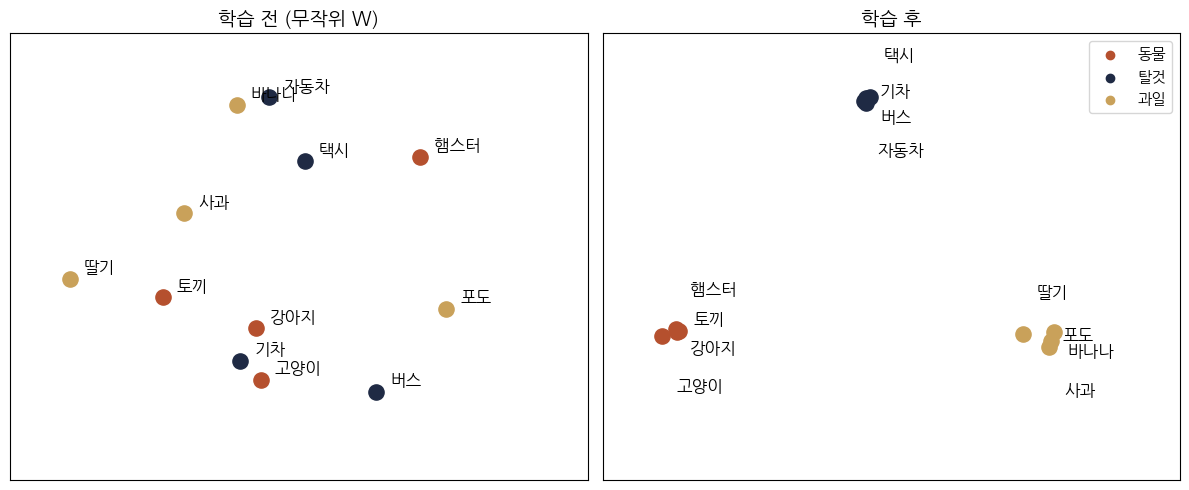

In [8]:
def pca_2d(X):
    Xc = X - X.mean(0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:2].T

colors = {'동물': '#B5502E', '탈것': '#1F2A44', '과일': '#C9A15A'}
labels = [('동물', w) for w in animals] + [('탈것', w) for w in vehicles] + [('과일', w) for w in fruits]
ids = [word2id[w] for _, w in labels]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, W_, title in [(axes[0], W_before, '학습 전 (무작위 W)'), (axes[1], W_after, '학습 후')]:
    P = pca_2d(W_[ids])
    P = P / np.abs(P).max(0)                        # 축 범위를 -1~1로 맞춤
    for k, ((g, w), (x, y)) in enumerate(zip(labels, P)):
        ax.scatter(x, y, s=120, color=colors[g])
        dy = 4 if W_ is W_before else -40 + 22 * (k % 4)   # 학습 후엔 점이 겹치므로 이름을 세로로 펼침
        ax.annotate(w, (x, y), xytext=(10, dy), textcoords='offset points', fontsize=12)
    ax.set_xlim(-1.3, 1.6); ax.set_ylim(-1.4, 1.4)
    ax.set_title(title, fontsize=14); ax.set_xticks([]); ax.set_yticks([])
for g, c in colors.items():
    axes[1].scatter([], [], color=c, label=g)
axes[1].legend(fontsize=11)
plt.tight_layout(); plt.show()

➡️ 학습 전에는 무작위로 흩어져 있던 단어들이, **문맥만 보고 학습한 뒤** 동물·탈것·과일끼리 모입니다. 이것이 분포 가설이고, 임베딩 공간에서 **거리 = 의미 차이**가 되는 이유입니다.

---
## 실습 2. Seq2Seq의 정보 병목 확인하기

번역 대신 결과를 확인하기 쉬운 **숫자열 뒤집기** 과제를 씁니다. 입력 `3 1 4 1 5` → 출력 `5 1 4 1 3`.
입력이 길어질수록 문맥 벡터 하나에 담아야 할 정보가 많아집니다.

- 토큰: `0` = 빈칸(PAD), `1~9` = 숫자, `10` = 시작 신호 `<sos>`
- 길이 5~30의 숫자열 20,000개로 학습, 2,000개로 평가

In [9]:
MAX_LEN, VOCAB, SOS = 30, 11, 10
rng = np.random.default_rng(0)

def make_data(n, min_len=5, max_len=MAX_LEN):
    enc_in  = np.zeros((n, MAX_LEN), int)   # 인코더 입력 (앞쪽을 0으로 채움)
    dec_in  = np.zeros((n, MAX_LEN), int)   # 디코더 입력: <sos> + 정답을 한 칸 민 것
    dec_out = np.zeros((n, MAX_LEN), int)   # 디코더 정답: 뒤집힌 숫자열
    lengths = rng.integers(min_len, max_len + 1, n)
    for i, L in enumerate(lengths):
        seq = rng.integers(1, 10, L)
        target = seq[::-1]
        enc_in[i, MAX_LEN - L:] = seq
        dec_out[i, :L] = target
        dec_in[i, 0], dec_in[i, 1:L] = SOS, target[:-1]
    return enc_in, dec_in, dec_out, lengths

Xe, Xd, Y, L_train = make_data(20000)
Te, Td, TY, L_test = make_data(2000)
i = int(np.where(L_test == 6)[0][0])   # 길이 6인 예제 하나 살펴보기
print('입력      :', Te[i]); print('디코더 입력:', Td[i]); print('정답      :', TY[i])

입력      : [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 6 3 2 2 7 4]
디코더 입력: [10  4  7  2  2  3  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0]
정답      : [4 7 2 2 3 6 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


이론 16–17번 슬라이드의 구조 그대로입니다. 인코더 LSTM의 **마지막 상태 (h, c)만** 디코더에 넘깁니다.
`use_attention=True`는 실습 3에서 씁니다.

In [10]:
def build_seq2seq(use_attention=False, units=64):
    enc_in = keras.Input((MAX_LEN,), name='encoder_input')
    dec_in = keras.Input((MAX_LEN,), name='decoder_input')

    # 인코더: 모든 시점의 은닉 상태(enc_seq)와 마지막 상태(h, c)를 돌려받는다
    enc_seq, h, c = layers.LSTM(units, return_sequences=True, return_state=True)(
        layers.Embedding(VOCAB, 32)(enc_in))

    # 디코더: 마지막 상태 (h, c) = 문맥 벡터에서 출발
    dec_seq = layers.LSTM(units, return_sequences=True)(
        layers.Embedding(VOCAB, 32)(dec_in), initial_state=[h, c])

    score_model = None
    if use_attention:   # Query=디코더 상태, Key=Value=인코더 은닉 상태들
        context, scores = layers.Attention(name='attention')(
            [dec_seq, enc_seq], return_attention_scores=True)
        dec_seq = layers.Concatenate()([dec_seq, context])
        score_model = keras.Model([enc_in, dec_in], scores)   # 가중치 확인용(실습 3-4)

    out = layers.Dense(VOCAB, activation='softmax')(dec_seq)
    model = keras.Model([enc_in, dec_in], out)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy')
    return model, score_model

seq2seq, _ = build_seq2seq(use_attention=False)
seq2seq.fit([Xe, Xd], Y, batch_size=128, epochs=10, validation_split=0.1, verbose=2)

Epoch 1/10
141/141 - 3s - 21ms/step - loss: 1.3345 - val_loss: 1.1550
Epoch 2/10
141/141 - 2s - 12ms/step - loss: 1.0294 - val_loss: 0.9049
Epoch 3/10
141/141 - 2s - 12ms/step - loss: 0.8149 - val_loss: 0.7260
Epoch 4/10
141/141 - 2s - 12ms/step - loss: 0.6898 - val_loss: 0.6577
Epoch 5/10
141/141 - 2s - 12ms/step - loss: 0.6146 - val_loss: 0.5662
Epoch 6/10
141/141 - 2s - 12ms/step - loss: 0.5517 - val_loss: 0.5268
Epoch 7/10
141/141 - 2s - 12ms/step - loss: 0.5108 - val_loss: 0.4869
Epoch 8/10
141/141 - 2s - 12ms/step - loss: 0.4720 - val_loss: 0.4607
Epoch 9/10
141/141 - 2s - 12ms/step - loss: 0.4407 - val_loss: 0.4439
Epoch 10/10
141/141 - 2s - 12ms/step - loss: 0.4159 - val_loss: 0.4007


In [11]:
BINS = [(5, 10), (11, 15), (16, 20), (21, 25), (26, 30)]
BIN_NAMES = [f'{lo}–{hi}' for lo, hi in BINS]

def accuracy_by_length(model):
    pred = model.predict([Te, Td], verbose=0).argmax(-1)
    acc = []
    for lo, hi in BINS:
        idx = [i for i in range(len(L_test)) if lo <= L_test[i] <= hi]
        acc.append(np.mean([np.mean(pred[i, :L_test[i]] == TY[i, :L_test[i]]) for i in idx]))
    return np.array(acc)

acc_plain = accuracy_by_length(seq2seq)
for name, a in zip(BIN_NAMES, acc_plain):
    print(f'길이 {name:>6s} : 정확도 {a:.1%}')

길이   5–10 : 정확도 95.7%
길이  11–15 : 정확도 89.5%
길이  16–20 : 정확도 80.8%
길이  21–25 : 정확도 71.2%
길이  26–30 : 정확도 63.3%


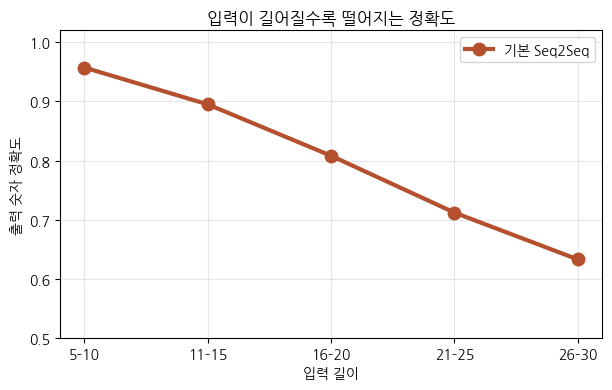

In [12]:
plt.figure(figsize=(7, 4))
plt.plot(BIN_NAMES, acc_plain, 'o-', color='#B5502E', lw=3, ms=9, label='기본 Seq2Seq')
plt.ylim(0.5, 1.02); plt.xlabel('입력 길이'); plt.ylabel('출력 숫자 정확도')
plt.title('입력이 길어질수록 떨어지는 정확도'); plt.grid(alpha=.3); plt.legend(); plt.show()

➡️ 같은 모델인데 **입력이 길어질수록 정확도가 떨어집니다.** 64차원짜리 (h, c) 하나에 30개의 숫자를 모두 담아야 하기 때문입니다 — 이론 18–19번 슬라이드의 **정보 병목**입니다.

---
## 실습 3. 어텐션: 손계산부터 모델까지

### 3-1. 소프트 딕셔너리 (이론 24번)

In [13]:
price = {'사과': 1000, '바나나': 3000, '포도': 5000}
print(price['바나나'])
try:
    price['바나니']
except KeyError as e:
    print('KeyError:', e)

weights = np.array([0.1, 0.8, 0.1])             # '바나니'가 각 키와 닮은 정도(설명용 값)
values  = np.array(list(price.values()))
print('소프트 딕셔너리 결과 =', weights @ values)

3000
KeyError: '바나니'
소프트 딕셔너리 결과 = 3000.0


### 3-2. 손계산 예제를 NumPy로 (이론 27–28번)

In [14]:
q = np.array([1., 2.])
K = np.array([[1., 0.], [0., 1.], [1., 1.]])     # k1, k2, k3
v = np.array([10., 20., 30.])                    # v1, v2, v3

scores  = K @ q                                  # ① 점수: q·kᵢ
weights = np.exp(scores) / np.exp(scores).sum()  # ② softmax
context = weights @ v                            # ③ 가중합
print('① 점수   :', scores)
print('② 가중치 :', weights, ' 합 =', weights.sum())
print('③ 문맥   :', round(context, 2))

① 점수   : [1. 2. 3.]
② 가중치 : [0.09  0.245 0.665]  합 = 1.0
③ 문맥   : 25.75


같은 계산을 Keras의 `Attention` 층에 맡겨 봅니다. 입력 순서는 `[query, value, key]`입니다.

In [15]:
att = layers.Attention()          # 기본값: 점수 = query와 key의 내적
out, w = att([q.reshape(1, 1, 2),        # query : (배치, Query 개수, 차원)
              v.reshape(1, 3, 1),        # value : (배치, 키 개수, 값 차원)
              K.reshape(1, 3, 2)],       # key   : (배치, 키 개수, 차원)
             return_attention_scores=True)
print('Keras 가중치:', np.asarray(w)[0, 0])
print('Keras 출력  :', round(float(np.asarray(out)[0, 0, 0]), 2))

Keras 가중치: [0.09  0.245 0.665]
Keras 출력  : 25.75


➡️ 손계산과 똑같습니다. Keras의 어텐션 층은 **내적 → softmax → 가중합**, 정확히 이론의 ①~③을 합니다.

### 3-3. 어텐션을 붙이면 병목이 풀릴까?
실습 2와 같은 데이터·같은 크기의 모델에 어텐션만 추가합니다.

In [16]:
seq2seq_att, score_model = build_seq2seq(use_attention=True)
seq2seq_att.fit([Xe, Xd], Y, batch_size=128, epochs=10, validation_split=0.1, verbose=2)

acc_att = accuracy_by_length(seq2seq_att)
for name, a, b in zip(BIN_NAMES, acc_plain, acc_att):
    print(f'길이 {name:>6s} : 기본 {a:6.1%}   어텐션 {b:6.1%}')

Epoch 1/10
141/141 - 3s - 23ms/step - loss: 1.3282 - val_loss: 1.0717
Epoch 2/10
141/141 - 2s - 14ms/step - loss: 0.7567 - val_loss: 0.4081
Epoch 3/10
141/141 - 2s - 14ms/step - loss: 0.2333 - val_loss: 0.1322
Epoch 4/10
141/141 - 2s - 14ms/step - loss: 0.0808 - val_loss: 0.0648
Epoch 5/10
141/141 - 2s - 14ms/step - loss: 0.0398 - val_loss: 0.0279
Epoch 6/10
141/141 - 2s - 14ms/step - loss: 0.0220 - val_loss: 0.0192
Epoch 7/10
141/141 - 2s - 14ms/step - loss: 0.0145 - val_loss: 0.0121
Epoch 8/10
141/141 - 2s - 14ms/step - loss: 0.0100 - val_loss: 0.0083
Epoch 9/10
141/141 - 2s - 14ms/step - loss: 0.0072 - val_loss: 0.0070
Epoch 10/10
141/141 - 2s - 14ms/step - loss: 0.0056 - val_loss: 0.0065
길이   5–10 : 기본  95.7%   어텐션 100.0%
길이  11–15 : 기본  89.5%   어텐션 100.0%
길이  16–20 : 기본  80.8%   어텐션 100.0%
길이  21–25 : 기본  71.2%   어텐션 100.0%
길이  26–30 : 기본  63.3%   어텐션  99.6%


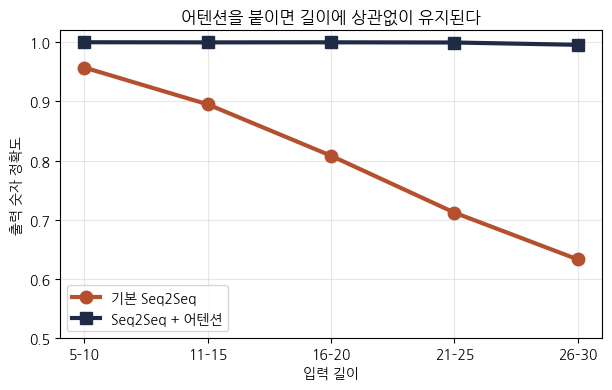

In [17]:
plt.figure(figsize=(7, 4))
plt.plot(BIN_NAMES, acc_plain, 'o-', color='#B5502E', lw=3, ms=9, label='기본 Seq2Seq')
plt.plot(BIN_NAMES, acc_att, 's-', color='#1F2A44', lw=3, ms=9, label='Seq2Seq + 어텐션')
plt.ylim(0.5, 1.02); plt.xlabel('입력 길이'); plt.ylabel('출력 숫자 정확도')
plt.title('어텐션을 붙이면 길이에 상관없이 유지된다'); plt.grid(alpha=.3); plt.legend(); plt.show()

### 3-4. 어텐션 가중치 들여다보기 (이론 29번)
디코더가 각 숫자를 출력할 때 입력의 어디를 봤는지 가중치를 꺼내 그립니다.

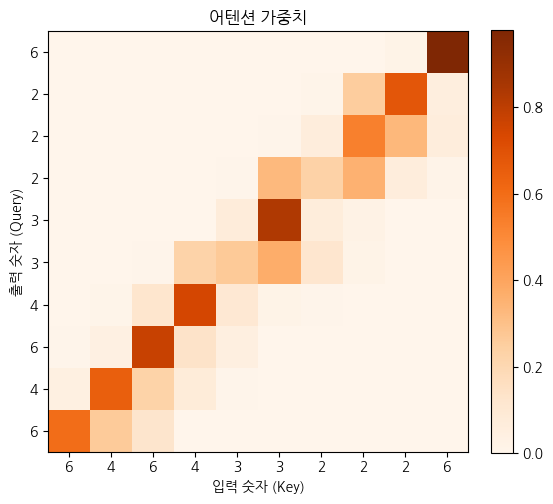

입력: [6 4 6 4 3 3 2 2 2 6] 
출력: [6 2 2 2 3 3 4 6 4 6]


In [18]:
# score_model은 학습된 seq2seq_att와 층을 공유하므로, 학습된 가중치를 그대로 보여 준다
i = int(np.where(L_test == 10)[0][0])            # 길이 10인 예제 하나
L = L_test[i]
A = score_model.predict([Te[i:i+1], Td[i:i+1]], verbose=0)[0][:L, MAX_LEN - L:]

src, tgt = Te[i, MAX_LEN - L:], TY[i, :L]
plt.figure(figsize=(6, 5.5))
plt.imshow(A, cmap='Oranges')
plt.xticks(range(L), src); plt.yticks(range(L), tgt)
plt.xlabel('입력 숫자 (Key)'); plt.ylabel('출력 숫자 (Query)')
plt.title('어텐션 가중치'); plt.colorbar(fraction=0.046); plt.show()
print('입력:', src, '\n출력:', tgt)

➡️ **반대 대각선**이 진하게 나타납니다. 첫 번째 출력은 입력의 마지막 숫자를, 마지막 출력은 입력의 첫 숫자를 봅니다.
아무도 "뒤집어서 보라"고 알려 주지 않았는데 모델이 스스로 **정렬(alignment)** 을 찾아낸 것입니다.

---
## 정리 및 도전 과제

| 이론 | 실습에서 확인한 것 |
|---|---|
| 원-핫은 의미를 못 담는다 | 내적 0, 거리 √2로 모두 같음 |
| 임베딩 층 = 룩업 테이블 | `emb(2)` = `W[2]` = 원-핫 × W |
| 분포 가설 | 문맥만으로 동물·탈것·과일이 모임 |
| Seq2Seq 정보 병목 | 길이가 길수록 정확도 하락 |
| 어텐션 = 내적 → softmax → 가중합 | NumPy 손계산 = Keras `Attention` |
| 어텐션이 병목을 해결 | 길이와 무관하게 정확도 유지, 반대 대각선 정렬 |

**도전 과제**
1. 실습 1-3의 템플릿에 새 범주(예: 직업 — 의사, 교사, 요리사)를 추가하고 2차원 그림에서 새 군집이 생기는지 확인해 보세요.
2. 실습 2의 `units=64`를 `256`으로 바꾸면 기본 Seq2Seq의 긴 입력 정확도는 어떻게 될까요? 병목이 사라졌다고 말할 수 있을까요?
3. 실습 3-2의 q를 `[3, 6]`으로 바꾸면 가중치가 어떻게 달라질까요? (힌트: 점수가 커지면 softmax는? → 다음 시간의 `√d`로 나누는 이유)

---
# 도전 과제 풀이

## 도전 과제 1

In [19]:
jobs = ['의사', '교사', '요리사', '경찰관']
templates4 = {**templates,
    'job': ['나는 매일 아침 {} 에게 인사 를 한다', '{} 가 직장 에서 열심히 일한다',
            '{} 가 되려고 시험 을 준비했다', '그 {} 는 월급 을 받았다']}
groups4 = {**groups, 'job': jobs}

keras.utils.set_random_seed(42)
rng4 = np.random.default_rng(0)
sentences4 = []
for _ in range(4000):                      # 범주가 4개이므로 문장도 4,000개로 (범주당 약 1,000개 유지)
    g = rng4.choice(list(groups4))
    sentences4.append(rng4.choice(templates4[g]).format(rng4.choice(groups4[g])).split())

words4 = sorted({w for s in sentences4 for w in s})
w2i4 = {w: i for i, w in enumerate(words4)}
pairs4 = np.array([(w2i4[s[i]], w2i4[s[j]])
                   for s in sentences4 for i in range(len(s))
                   for j in range(max(0, i - 2), min(len(s), i + 3)) if i != j])
V4 = len(words4)
print('어휘 크기 V =', V4, '| 학습 쌍 개수:', len(pairs4))

model4 = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Embedding(V4, D, name='embedding'),
    layers.Flatten(),
    layers.Dense(V4, activation='softmax'),
])
W4_before = model4.get_layer('embedding').get_weights()[0].copy()
model4.compile(optimizer='adam', loss='sparse_categorical_crossentropy')
model4.fit(pairs4[:, 0], pairs4[:, 1], epochs=5, batch_size=256, verbose=2)
W4_after = model4.get_layer('embedding').get_weights()[0]

어휘 크기 V = 75 | 학습 쌍 개수: 83852
Epoch 1/5
328/328 - 0s - 914us/step - loss: 4.0047
Epoch 2/5
328/328 - 0s - 362us/step - loss: 3.1780
Epoch 3/5
328/328 - 0s - 338us/step - loss: 2.7802
Epoch 4/5
328/328 - 0s - 330us/step - loss: 2.5827
Epoch 5/5
328/328 - 0s - 332us/step - loss: 2.4583


In [20]:
targets4 = animals + vehicles + fruits + jobs
def most_similar4(word, W, k=3):
    sims = {w: cosine(W[w2i4[word]], W[w2i4[w]]) for w in targets4 if w != word}
    return sorted(sims.items(), key=lambda x: -x[1])[:k]

for w in ['고양이', '버스', '사과', '의사', '교사']:
    print(f'{w:4s} 와 가장 가까운 단어:', [(x, round(float(s), 2)) for x, s in most_similar4(w, W4_after)])

# 범주 안 / 범주 사이 평균 코사인 유사도
cats4 = {'동물': animals, '탈것': vehicles, '과일': fruits, '직업': jobs}
def mean_cos(A, B, W):
    return np.mean([cosine(W[w2i4[a]], W[w2i4[b]]) for a in A for b in B if a != b])
print()
print('       ' + ''.join(f'{c:>8s}' for c in cats4))
for c1, A in cats4.items():
    print(f'{c1:4s} ' + ''.join(f'{mean_cos(A, B, W4_after):8.2f}' for B in cats4.values()))

고양이  와 가장 가까운 단어: [('토끼', 0.99), ('강아지', 0.99), ('햄스터', 0.97)]
버스   와 가장 가까운 단어: [('기차', 0.97), ('자동차', 0.96), ('택시', 0.95)]
사과   와 가장 가까운 단어: [('바나나', 1.0), ('딸기', 1.0), ('포도', 1.0)]
의사   와 가장 가까운 단어: [('요리사', 1.0), ('교사', 1.0), ('경찰관', 0.99)]
교사   와 가장 가까운 단어: [('요리사', 1.0), ('의사', 1.0), ('경찰관', 0.99)]

             동물      탈것      과일      직업
동물       0.99    0.08    0.27    0.78
탈것       0.08    0.98    0.12   -0.49
과일       0.27    0.12    1.00    0.15
직업       0.78   -0.49    0.15    1.00


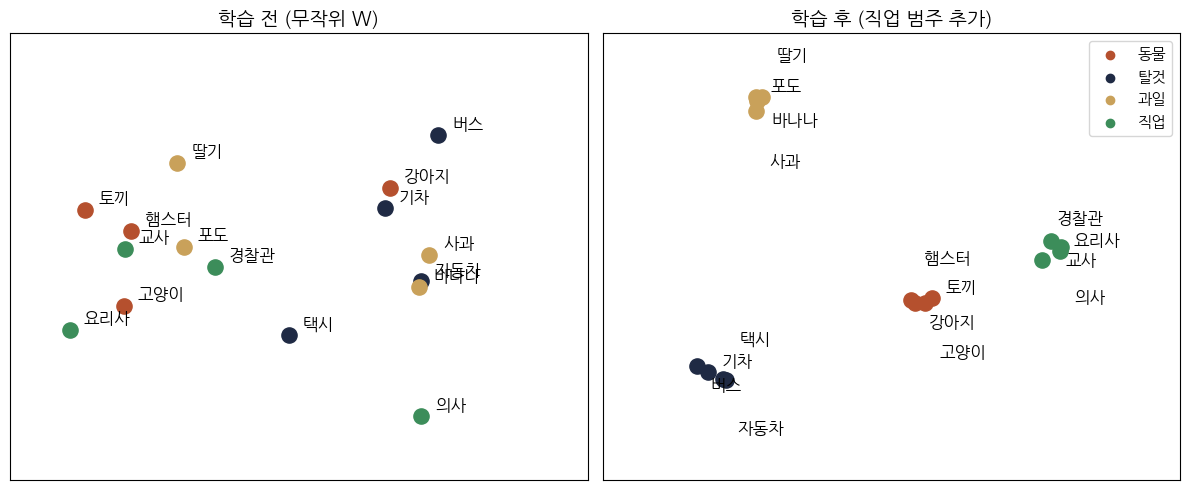

In [21]:
colors4 = {**colors, '직업': '#3C8D5A'}
labels4 = labels + [('직업', w) for w in jobs]
ids4 = [w2i4[w] for _, w in labels4]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, W_, title in [(axes[0], W4_before, '학습 전 (무작위 W)'), (axes[1], W4_after, '학습 후 (직업 범주 추가)')]:
    P = pca_2d(W_[ids4])
    P = P / np.abs(P).max(0)
    for k, ((g, w), (x, y)) in enumerate(zip(labels4, P)):
        ax.scatter(x, y, s=120, color=colors4[g])
        dy = 4 if W_ is W4_before else -40 + 22 * (k % 4)
        ax.annotate(w, (x, y), xytext=(10, dy), textcoords='offset points', fontsize=12)
    ax.set_xlim(-1.3, 1.6); ax.set_ylim(-1.4, 1.4)
    ax.set_title(title, fontsize=14); ax.set_xticks([]); ax.set_yticks([])
for g, c in colors4.items():
    axes[1].scatter([], [], color=c, label=g)
axes[1].legend(fontsize=11)
plt.tight_layout(); plt.show()

## 도전 과제 2

In [22]:
keras.utils.set_random_seed(42)
seq2seq_256, _ = build_seq2seq(use_attention=False, units=256)
seq2seq_256.fit([Xe, Xd], Y, batch_size=128, epochs=10, validation_split=0.1, verbose=2)
acc_256 = accuracy_by_length(seq2seq_256)

print(f"{'길이':>8s} | {'기본 64':>8s} | {'기본 256':>8s} | {'어텐션 64':>8s}")
for name, a, b, c in zip(BIN_NAMES, acc_plain, acc_256, acc_att):
    print(f'{name:>8s} | {a:8.1%} | {b:8.1%} | {c:8.1%}')
print()
print('파라미터 수  기본 64 :', f'{seq2seq.count_params():,}')
print('파라미터 수  기본 256:', f'{seq2seq_256.count_params():,}')
print('파라미터 수  어텐션 64:', f'{seq2seq_att.count_params():,}')

Epoch 1/10
141/141 - 8s - 54ms/step - loss: 1.3432 - val_loss: 1.2029
Epoch 2/10
141/141 - 6s - 45ms/step - loss: 0.9422 - val_loss: 0.6367
Epoch 3/10
141/141 - 6s - 45ms/step - loss: 0.4816 - val_loss: 0.3509
Epoch 4/10
141/141 - 6s - 46ms/step - loss: 0.3012 - val_loss: 0.2616
Epoch 5/10
141/141 - 6s - 45ms/step - loss: 0.2212 - val_loss: 0.1962
Epoch 6/10
141/141 - 6s - 45ms/step - loss: 0.1802 - val_loss: 0.1808
Epoch 7/10
141/141 - 6s - 45ms/step - loss: 0.1549 - val_loss: 0.1583
Epoch 8/10
141/141 - 6s - 45ms/step - loss: 0.1324 - val_loss: 0.1297
Epoch 9/10
141/141 - 6s - 46ms/step - loss: 0.1178 - val_loss: 0.1209
Epoch 10/10
141/141 - 6s - 45ms/step - loss: 0.1028 - val_loss: 0.1132
      길이 |    기본 64 |   기본 256 |   어텐션 64
    5–10 |    95.7% |   100.0% |   100.0%
   11–15 |    89.5% |    99.7% |   100.0%
   16–20 |    80.8% |    97.8% |   100.0%
   21–25 |    71.2% |    93.1% |   100.0%
   26–30 |    63.3% |    86.0% |    99.6%

파라미터 수  기본 64 : 51,083
파라미터 수  기본 256: 595,403

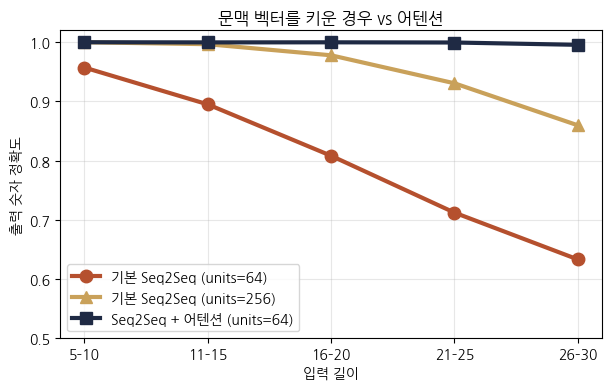

In [23]:
plt.figure(figsize=(7, 4))
plt.plot(BIN_NAMES, acc_plain, 'o-', color='#B5502E', lw=3, ms=9, label='기본 Seq2Seq (units=64)')
plt.plot(BIN_NAMES, acc_256, '^-', color='#C9A15A', lw=3, ms=9, label='기본 Seq2Seq (units=256)')
plt.plot(BIN_NAMES, acc_att, 's-', color='#1F2A44', lw=3, ms=9, label='Seq2Seq + 어텐션 (units=64)')
plt.ylim(0.5, 1.02); plt.xlabel('입력 길이'); plt.ylabel('출력 숫자 정확도')
plt.title('문맥 벡터를 키운 경우 vs 어텐션'); plt.grid(alpha=.3); plt.legend(); plt.show()

결과: 정확도는 크게 오르지만, 병목이 사라졌다고 할 수는 없음.

## 도전 과제 3

In [24]:
def softmax(x):
    e = np.exp(x - x.max())
    return e / e.sum()

d = K.shape[1]   # key 차원 = 2
print(f"{'q':>12s} | {'점수':>16s} | {'softmax 가중치':>24s} | 문맥")
for q_ in [np.array([1., 2.]), np.array([3., 6.]), np.array([10., 20.])]:
    s = K @ q_
    w_ = softmax(s)
    print(f'{str(q_):>12s} | {str(s):>16s} | {str(w_):>24s} | {w_ @ v:.2f}')

print('\n--- 점수를 √d 로 나눈 경우 (scaled dot-product) ---')
for q_ in [np.array([1., 2.]), np.array([3., 6.])]:
    s = K @ q_ / np.sqrt(d)
    w_ = softmax(s)
    print(f'{str(q_):>12s} | {str(np.round(s, 3)):>16s} | {str(w_):>24s} | {w_ @ v:.2f}')

           q |               점수 |              softmax 가중치 | 문맥
     [1. 2.] |       [1. 2. 3.] |      [0.09  0.245 0.665] | 25.75
     [3. 6.] |       [3. 6. 9.] |      [0.002 0.047 0.95 ] | 29.48
   [10. 20.] |    [10. 20. 30.] |               [0. 0. 1.] | 30.00

--- 점수를 √d 로 나눈 경우 (scaled dot-product) ---
     [1. 2.] | [0.707 1.414 2.121] |      [0.14  0.284 0.576] | 24.36
     [3. 6.] | [2.121 4.243 6.364] |      [0.013 0.106 0.882] | 28.69


In [25]:
# Keras Attention 층으로도 확인
out3, w3 = layers.Attention()([np.array([3., 6.]).reshape(1, 1, 2), v.reshape(1, 3, 1), K.reshape(1, 3, 2)],
                              return_attention_scores=True)
print('Keras 가중치 (q=[3,6]):', np.asarray(w3)[0, 0])
print('Keras 출력   (q=[3,6]):', round(float(np.asarray(out3)[0, 0, 0]), 2))

# softmax 기울기: 가중치가 한쪽으로 쏠릴수록 작아진다 (∂wᵢ/∂sᵢ = wᵢ(1−wᵢ))
for q_ in [np.array([1., 2.]), np.array([3., 6.]), np.array([10., 20.])]:
    w_ = softmax(K @ q_)
    print(f'q={str(q_):>10s}  max ∂wᵢ/∂sᵢ = {np.max(w_ * (1 - w_)):.4f}')

Keras 가중치 (q=[3,6]): [0.002 0.047 0.95 ]
Keras 출력   (q=[3,6]): 29.48
q=   [1. 2.]  max ∂wᵢ/∂sᵢ = 0.2227
q=   [3. 6.]  max ∂wᵢ/∂sᵢ = 0.0472
q= [10. 20.]  max ∂wᵢ/∂sᵢ = 0.0000
